# AML Midterm — Part 1 experiment report

**Final candidate validation F1: 0.85043.** Macro F1: 0.68841, measured on all 78 validation rows. The model configuration and threshold were unchanged. Its test probabilities match the delivered submission.

The candidate's **0.93631 training-only grouped leave-one-out F1 did not transfer to validation**. No improvement over the user's existing model has been demonstrated, and a leaderboard win is not established. The initial bagged-model comparison also had a best sample-F1 of 0.85043; these are separate measurements. Historical search and first-comparison details follow.


## Requested final-candidate evaluation

| Reason | Validation F1 |
|---|---:|
| Safety | 0.87500 |
| Funding | 0.40000 |
| Efficacy | 0.72000 |
| Recruitment | 0.97087 |
| Other | 0.47619 |

Source: `experiments/final-validation.json`. Reproducible evaluation: `evaluate_final_validation.py`. This evaluation does not alter any training labels, settings, threshold, or Kaggle predictions.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root = Path.cwd()
if not (root / 'experiments').exists():
    root = root.parent
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
figdir = root / 'figures'; figdir.mkdir(exist_ok=True)
labels = ['Safety','Funding','Efficacy','Recruitment','Other']
train = pd.read_csv(root/'data/part1_train.csv')
known = train[labels].ge(0).all(axis=1)
trials = pd.read_csv(root/'experiments/trials.csv')
val = json.loads((root/'experiments/validation-once.json').read_text())
final = json.loads((root/'experiments/final-candidate.json').read_text())


## Data and constraints

1,171 training trials: 157 labeled, 1,014 wholly masked. The 78 validation trials are separate. The 312 test trials start later, in 2010–2016. The main target is sample-wise multilabel F1; per-reason and macro F1 are also retained. There are 150 unique embedding groups among the 157 labeled rows. Exact duplicate groups remain together in CV, and their masked counterparts are excluded from fold fitting. IDs are identifiers only.

Funding has only eight positive training examples. The known labels mostly come from early years, plus a selected rare-reason enrichment sample. Random-fold CV does not reproduce the future-test distribution.

,positive_training_examples
Safety,16
Funding,8
Efficacy,17
Recruitment,101
Other,25


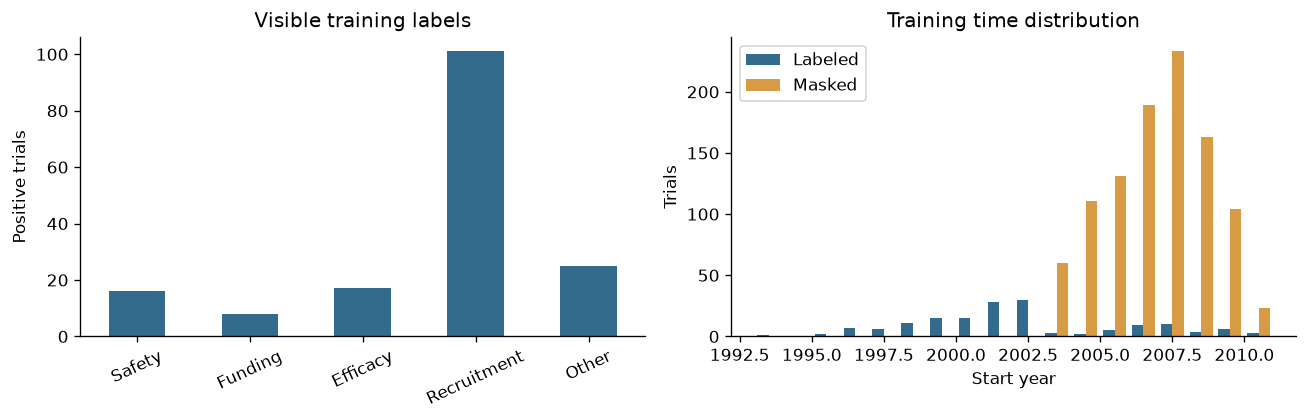

In [2]:
display(pd.DataFrame({'positive_training_examples': train.loc[known,labels].sum()}))
fig, axes = plt.subplots(1,2,figsize=(11,3.6))
train.loc[known,labels].sum().plot.bar(ax=axes[0], color='#326b8c', rot=25)
axes[0].set(title='Visible training labels', ylabel='Positive trials')
axes[1].hist([train.loc[known,'start_year'], train.loc[~known,'start_year']], bins=range(1993,2012), label=['Labeled','Masked'], color=['#326b8c','#d79a45'])
axes[1].set(title='Training time distribution', xlabel='Start year', ylabel='Trials'); axes[1].legend()
fig.tight_layout(); fig.savefig(figdir/'data_distribution.png'); fig.savefig(figdir/'data_distribution.pdf'); plt.show()


## Evaluation design

The broad screen used grouped multilabel-stratified five-fold CV. Scaling, TF-IDF vocabularies, PCA, clustering, label mapping, feature transforms and pseudo-labeling are fitted on training-fold labels plus permitted masked training rows. Held-out rows never participate in preprocessing or pseudo-label generation. A test verifies that changing held-out labels, query values, or IDs cannot change fitted predictions for other rows.

Promising methods were repeated on three fresh split seeds. Added fields were screened individually, followed by selected combinations and an all-fields comparison. Decision policies were a small fixed threshold grid, argmax, or exact expected-F1 enumeration under independent marginal probabilities. Extensive selection makes these scores optimistic.

A five-outer/three-inner conditional nested audit selected both models and decision rules inside each outer fold. It scored 0.89384. Because the shortlist was informed by earlier full-training exploration, this is not an unbiased assessment of the entire adaptive search. Chronological cutoffs add a separate stress test, but later labeled rows are intentionally enriched for rare classes.

A three-candidate shortlist was frozen before the first external validation evaluation. After its disappointing result, subsequent model development remained training-only. The final candidate was later evaluated at the user’s request, with no threshold or model retuning. Leave-one-embedding-group-out CV then checked a nearly full-size training regime (150 groups, around 156 labeled rows per fit).

## Model-family comparisons

The table reports each family’s **best development result**, not an unbiased ranking. Counts include successful unique configurations and CV runs; repeated seeds are separate runs. The failed full-dimensional QDA attempt is retained in the ledger; reduced-dimensional variants were subsequently evaluated.

Clustering includes centroid-based K-Means and bisecting K-Means, Gaussian mixtures, hierarchical agglomeration, spectral clustering, BIRCH, DBSCAN and HDBSCAN. Label propagation uses normalized graph diffusion or hard-clamped graph inference. Supervised comparisons include logistic/linear and kernel SVM, neighbors, ridge/kernel ridge, shrinkage discriminants, Gaussian NB, random/extra trees, three boosting libraries, classifier chains, powerset and soft multiclass models, Gaussian processes, NCA and PLS. Additional tests include semi-supervised EM, Laplacian-regularized kernels, prototype dictionaries and consensus pseudo-labeling.

,family,best_development_f1,configurations,cv_runs
0,svc,0.9406,159,228
1,pseudo,0.9384,78,107
2,cluster_features,0.9363,28,32
3,chain,0.9363,1,4
4,logistic,0.9329,103,115
5,laprls,0.9278,12,16
6,powerset,0.9268,17,24
7,softmax,0.9257,16,20
8,metric_graph,0.9214,18,18
9,pls,0.9151,6,6


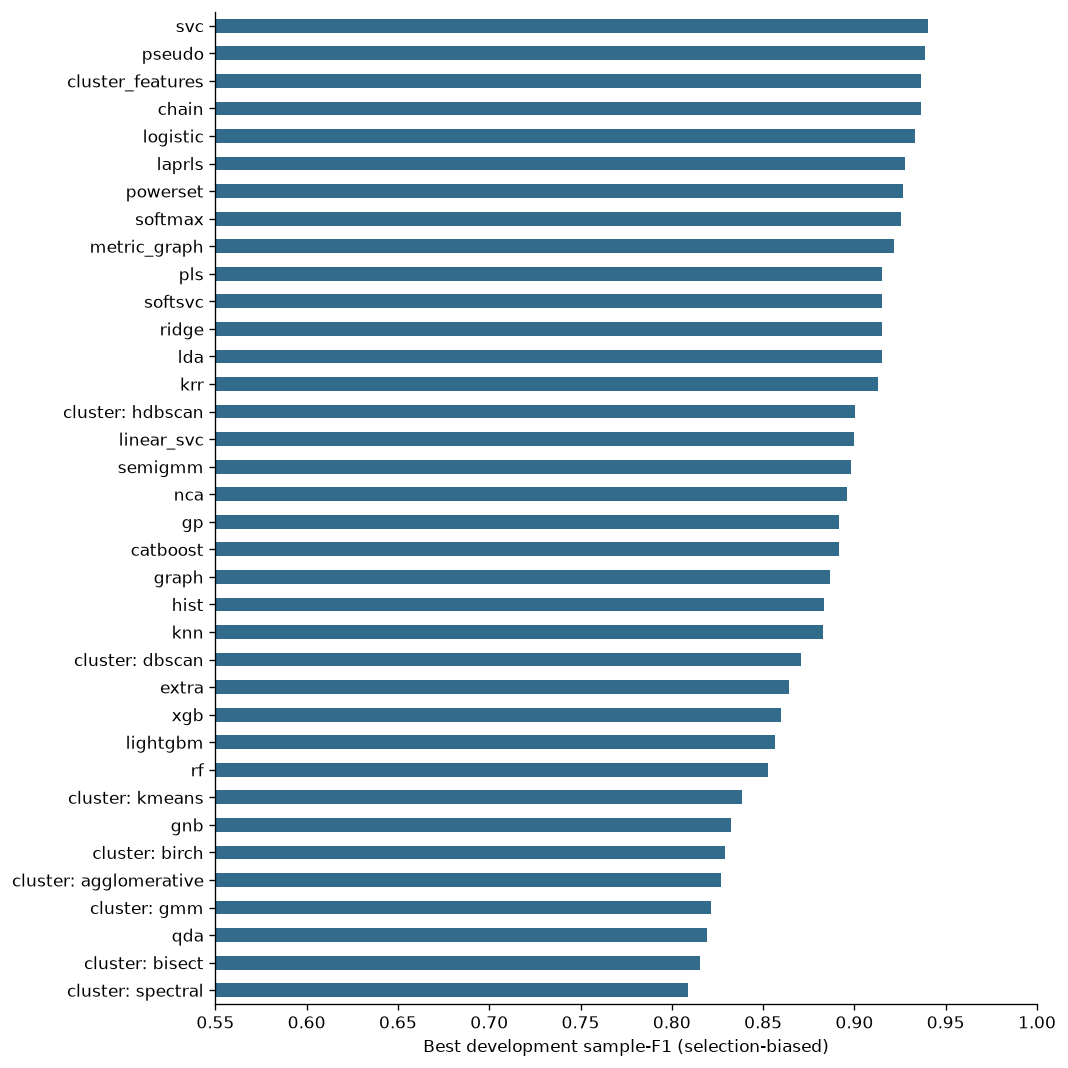

In [3]:
families = pd.read_csv(root/'experiments/model-family-summary.csv')
display(families[['family','best_development_f1','configurations','cv_runs']].round(4))
fig, ax = plt.subplots(figsize=(9,9))
families.sort_values('best_development_f1').plot.barh(x='family',y='best_development_f1',ax=ax,legend=False,color='#326b8c')
ax.set(xlim=(0.55,1),xlabel='Best development sample-F1 (selection-biased)',ylabel='')
fig.tight_layout(); fig.savefig(figdir/'model_families.png'); plt.show()


## Features and preprocessing

All 150 rotated reason coordinates are kept as a block. Standard scaling, rotation-preserving global scaling, row normalization, PCA dimensions and whitening strengths were compared. Auxiliary groups include year, eligibility word/bigram and character TF-IDF, disease names, drugs, ICD codes, matched drugs, targets, actions, pathways, broad pathway filtering, pathway-depth counts, Morgan fingerprints, molecular descriptors, missingness and field counts. Each group was initially added alone at several weights.

The first-seed result is the selection score. When available, the fresh-seed mean below uses that first-seed decision rule unchanged. A missing fresh-seed value means the configuration was screened out or another configuration was repeated; it is not evidence of a gain. Some apparent improvements disappeared across splits. Chemistry and selected drug/text blocks were retained in the final candidate because of repeated-CV and combination checks, not per-validation-row edits. More features can overwhelm a tiny labeled set, alter kernel distances and encode fragile disease/year associations. Fingerprint missingness also reflects incomplete drug matching.

,feature,model,weight,first_seed_f1,rule_frozen_on_first_seed,fresh_seed_mean_f1,n_fresh_seeds
0,counts,svc,0.50,0.9257,t0.55,NaN,0
1,criteria,svc,1.00,0.9299,expected_f1,0.9122,3
2,criteria_char,svc,1.00,0.9278,t0.35,NaN,0
3,descriptors,svc,0.50,0.9321,t0.35,0.9008,3
4,diseases_cleaned,svc,0.15,0.9257,t0.45,NaN,0
5,drug_actions,logistic,0.15,0.9214,t0.25,NaN,0
6,drug_pathways,svc,0.15,0.9299,t0.45,0.8938,3
7,drug_targets,svc,1.00,0.9289,expected_f1,0.9142,3
8,drugs,svc,0.50,0.9363,t0.35,0.9062,3
9,fingerprint,svc,0.50,0.9321,t0.45,0.9091,3


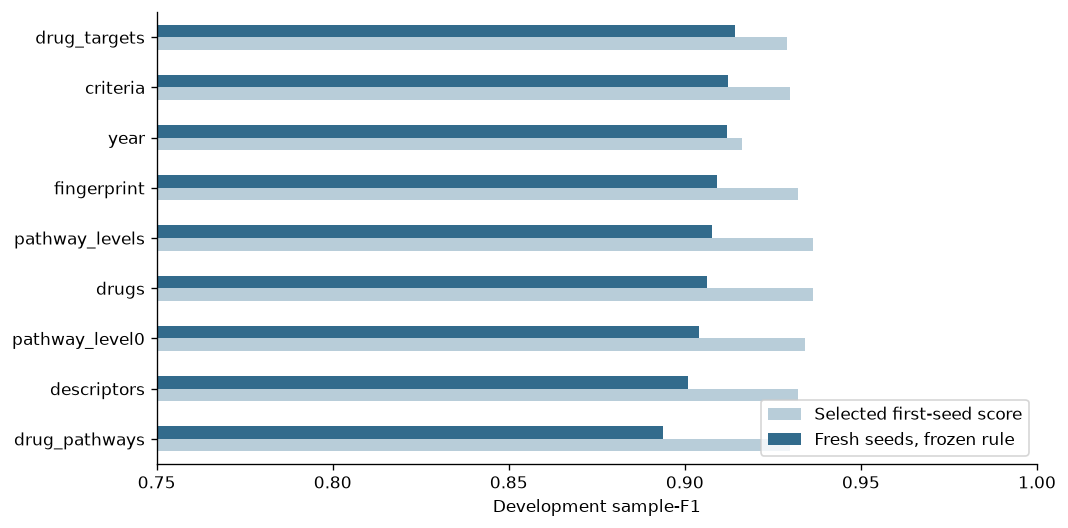

In [4]:
ablation = pd.read_csv(root/'experiments/feature-ablation.csv')
display(ablation.round(4))
repeat = ablation.dropna(subset=['fresh_seed_mean_f1']).sort_values('fresh_seed_mean_f1')
fig, ax = plt.subplots(figsize=(9,4.5))
repeat.plot.barh(x='feature',y=['first_seed_f1','fresh_seed_mean_f1'],ax=ax,color=['#b8cdd9','#326b8c'])
ax.set(xlim=(.75,1),xlabel='Development sample-F1',ylabel=''); ax.legend(['Selected first-seed score','Fresh seeds, frozen rule'],loc='lower right')
fig.tight_layout(); fig.savefig(figdir/'feature_robustness.png'); plt.show()


## External validation — preserve the disappointing result

These are the three models in the initial frozen external-validation comparison. The final full-fit candidate was evaluated separately at the user’s request; see the latest result above. All model definitions and thresholds were fixed beforehand. The selected validation result has selection optimism, and 78 rows leave wide uncertainty. It is lower than the user’s approximate previous validation performance. **No leaderboard improvement is established.**

In [5]:
vtable = pd.DataFrame([{k:r[k] for k in ['name','sample_f1','macro_f1']+[f'f1_{l}' for l in labels]} for r in val['candidates']])
display(vtable.round(5))
print('Selected-model grouped bootstrap 95% interval:', val['bootstrap_95_interval'])
nested = json.loads((root/'experiments/nested-audit.json').read_text())
print('Conditional nested shortlist sample-F1:', nested['sample_f1'])
temporal = pd.read_json(root/'experiments/temporal-audit.json')
display(temporal[['cutoff','n_train','n_test','sample_f1','macro_f1']].round(4))


,name,sample_f1,macro_f1,f1_Safety,f1_Funding,f1_Efficacy,f1_Recruitment,f1_Other
0,fingerprint_ssl,0.85043,0.68655,0.875,0.4,0.72000,0.96154,0.47619
1,balanced_ensemble,0.84188,0.67775,0.875,0.4,0.66667,0.97087,0.47619
2,embedding_ssl,0.85043,0.68948,0.875,0.4,0.72000,0.95238,0.50000


Selected-model grouped bootstrap 95% interval: [0.7705627705627704, 0.9178082191780822]
Conditional nested shortlist sample-F1: 0.8938428874734606


,cutoff,n_train,n_test,sample_f1,macro_f1
0,2002,115,42,0.8571,0.8212
1,2002,115,42,0.8889,0.8855
2,2002,115,42,0.7778,0.6496
3,2002,115,42,0.8492,0.7080
4,2002,115,42,0.8730,0.8740
5,2002,115,42,0.8254,0.6986
6,2002,115,42,0.8571,0.8008
7,2005,125,32,0.8646,0.8473
8,2005,125,32,0.8333,0.8147
9,2005,125,32,0.7813,0.7456


## Final full-training candidate and augmentation

The final candidate uses all 157 true labeled rows, unlike the earlier 15-model fold-bagging prediction strategy. It is a 50% HDBSCAN-consensus pseudo-label logistic model with Morgan fingerprints, 25% RBF SVM with criteria/drug TF-IDF, and 25% RBF SVM with target TF-IDF.

For the pseudo-label component, HDBSCAN is fitted to 25 PCA coordinates of standardized reason embeddings, without labels. Cluster labels are mapped using gold fold-training rows; noise/unlabeled clusters fall back to a distance-weighted labeled-neighbor estimate. A separate logistic model supplies the second view. Only agreed binary labels with average confidence at least 0.95 are accepted into the per-label fit, each at weight 0.05. Original true labels are retained. The auxiliary fingerprint uses radius 2 and 1,024 bits, max-pooled across valid supplied molecules; unmatched/invalid molecules contribute zero.

For final predictions, member probabilities use fixed weights 0.50/0.25/0.25 and a 0.35 threshold, with highest-probability fallback for empty predictions. Every masked row receives five binary labels. Pseudo-labels are predictions, not newly verified ground truth. The final prediction recipe and SHA256 are saved in `final-candidate.json`. The exact final candidate was subsequently evaluated on validation at the user’s request: **0.85043 sample-F1**. Its 0.93631 leave-group-out score remains a selection-biased development estimate and is substantially higher than the observed validation result.

In [6]:
display(pd.DataFrame([{'candidate':r['name'],'leave_group_out_f1':r['fullsize_oof_f1'],'rule':r['rule']} for r in json.loads((root/'experiments/fullsize-ranking.json').read_text())]))
print('Final CSV:', final['submission'])
print('Kaggle score:', final['kaggle_score'])
aug = pd.read_csv(root/'predictions/part1_train_augmented_fullfit.csv')
display(aug.groupby('label_source')[labels].sum())
print('Ground truth rows unchanged:', np.array_equal(aug.loc[known,labels].to_numpy(),train.loc[known,labels].to_numpy()))
print('Generated masked rows:', (~known).sum())


,candidate,leave_group_out_f1,rule
0,balanced_ensemble,0.936306,t0.35
1,fingerprint_ssl,0.932059,t0.35
2,embedding_ssl,0.929936,expected_f1


Final CSV: predictions/part1_fullfit_candidate.csv
Kaggle score: None


,Safety,Funding,Efficacy,Recruitment,Other
label_source,,,,,
fullfit_pseudo_label,85,15,98,730,142
original,16,8,17,101,25


Ground truth rows unchanged: True
Generated masked rows: 1014


## Limitations and next step

The requested winning score is **not achieved or verified**. The final candidate does not demonstrate an improvement on validation; do not infer a leaderboard improvement from its CV score. The first holdout failure is evidence against assuming that the higher CV values transfer. The full-fit candidate also scored 0.85043 on validation, confirming that the training-size change did not solve the measured gap.

The broad search was structured, not exhaustive. Reusing tiny training folds for many choices creates selection bias despite strict per-fit leakage controls. Rare-label estimates are unstable; the temporal sampling scheme differs from both ordinary CV and future tests. Strong uncertainty, pseudo-label error and class-distribution shifts remain. Part 2 and the final combined five-page assignment report are outside this Part 1 package.

## References

- [Semi-supervised learning (scikit-learn documentation)](https://scikit-learn.org/stable/modules/semi_supervised.html) — Graph propagation/spreading and confidence-controlled pseudo-labeling; not an external source of trial records.

- [Nested versus non-nested cross-validation (scikit-learn)](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html) — Separate model-selection scores from estimates of generalization.

- [Clustering (scikit-learn documentation)](https://scikit-learn.org/stable/modules/clustering.html) — Compare geometric assumptions and inductive extensions for multiple cluster families.

- [Zhu, Ghahramani, Lafferty (2003), Semi-Supervised Learning Using Gaussian Fields and Harmonic Functions](https://www.cs.cornell.edu/courses/cs6241/2019sp/readings/ZGL-2003-SSL.pdf) — Harmonic graph inference with known-label boundary conditions.

- [Zhou et al. (2004), Learning with Local and Global Consistency](https://www.cs.cornell.edu/courses/cs6241/2020sp/readings/Zhou-2004-global-local.pdf) — Normalized graph diffusion; custom multi-output implementation.

- [Waegeman et al. (2014), On the Bayes-Optimality of F-Measure Maximizers](https://jmlr.org/papers/v15/waegeman14a.html) — Decision-theoretic motivation for sample-F1 decoder. Our simple enumeration uses independent marginal probabilities, not the full GFM joint-distribution algorithm.

- [Read et al. (2009), Classifier Chains for Multi-label Classification](https://ml.cms.waikato.ac.nz/publications/2009/chains.pdf) — Evaluate label-dependence models with cross-fitted chain features.

- [RDKit Getting Started](https://www.rdkit.org/docs/GettingStartedInPython.html) — Morgan fingerprints and numerical descriptors computed only from supplied SMILES.